# Lab 4 — Notebook 3: Pose Estimation · Tiger-pose

**Group members:** *Elias Hawkins & Davin Matias*

**Task:** Locate 12 keypoints on each tiger  
**Dataset:** `tiger-pose.yaml`  
**Starting weights:** `yolo26n-pose.pt`

**Constraints (from the lab manual):**
- Ultralytics YOLO on Google Colab with a T4 GPU
- Nano (`n`) model only
- `imgsz=640`, `batch=16`, `seed=0`
- Epochs: **50–150** (you choose within this range)
- Save training runs to Google Drive
- Predictions and reflection answers must be your own writing (no AI)

Work top to bottom. Write each **Prediction** *before* you run the code that follows it.


---
## Step 0: Setup and data check

Install Ultralytics, mount Drive, load the dataset, and verify it matches the lab tables.


### Install and imports


In [11]:
# Runtime → Change runtime type → T4 GPU (recommended)
!pip -q install ultralytics


In [12]:
import os
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import ultralytics
from IPython.display import Image as IPImage
from IPython.display import display
from PIL import Image
from ultralytics import YOLO
from ultralytics.data.utils import check_det_dataset

print("Ultralytics:", ultralytics.__version__)
ultralytics.checks()


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Setup complete ✅ (2 CPUs, 12.7 GB RAM, 0.2/112.6 GB disk)


### Mount Google Drive (so disconnects don't erase training runs)


In [13]:
from google.colab import drive

drive.mount("/content/drive")

# Change this if you want a different save location on Drive
DRIVE_ROOT = Path("/content/drive/MyDrive/IT480_Lab4")
DRIVE_ROOT.mkdir(parents=True, exist_ok=True)
print("Saving runs under:", DRIVE_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Saving runs under: /content/drive/MyDrive/IT480_Lab4


### Config for this notebook

Expected dataset (from the lab manual):

| Property | Value |
| --- | --- |
| Classes | 1: tiger |
| Keypoints | 12 per tiger `(x, y)` — no visibility flag |
| Images | 263 total: 210 train / 53 val / **no test split** |
| Label format | `class xc yc w h kx1 ky1 ... kx12 ky12` |


In [14]:
# ---- Notebook config ----
TASK = "pose"
DATA_YAML = "tiger-pose.yaml"
WEIGHTS = "yolo26n-pose.pt"
IMGSZ = 640
BATCH = 16
SEED = 0

# YOU choose epochs within 50–150 (fill Prediction 2 before changing this)
EPOCHS = 100  # TODO: set your chosen epoch count

PROJECT_DIR = DRIVE_ROOT / "pose"
RUN_NAME = "pose_run"
PROJECT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Task={TASK} | data={DATA_YAML} | weights={WEIGHTS}")
print(f"epochs={EPOCHS} | imgsz={IMGSZ} | batch={BATCH} | seed={SEED}")
print(f"project={PROJECT_DIR} | name={RUN_NAME}")


Task=pose | data=tiger-pose.yaml | weights=yolo26n-pose.pt
epochs=100 | imgsz=640 | batch=16 | seed=0
project=/content/drive/MyDrive/IT480_Lab4/pose | name=pose_run


### Download / locate the dataset and print class names + split sizes


In [15]:
# check_det_dataset downloads the zip on first use and returns parsed YAML fields
data_info = check_det_dataset(DATA_YAML)

DATA_ROOT = Path(data_info["path"])
NAMES = data_info["names"]
if isinstance(NAMES, list):
    NAMES = {i: n for i, n in enumerate(NAMES)}

print("Dataset root:", DATA_ROOT)
print("Class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")
print("Number of classes:", len(NAMES))

kpt_shape = data_info.get("kpt_shape")
print("Dataset kpt_shape:", kpt_shape)


def list_images(split: str):
    split_rel = data_info.get(split)
    if not split_rel:
        return []
    # YAML values are relative to DATA_ROOT (e.g. "images/train")
    split_dir = Path(split_rel)
    if not split_dir.is_absolute():
        split_dir = DATA_ROOT / split_dir
    if not split_dir.exists():
        return []
    return sorted(
        p for p in split_dir.rglob("*")
        if p.suffix.lower() in {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    )

train_imgs = list_images("train")
val_imgs = list_images("val")
test_imgs = list_images("test")

print("\nImage counts:")
print(f"  train: {len(train_imgs)}")
print(f"  val:   {len(val_imgs)}")
print(f"  test:  {len(test_imgs)}")
print(f"  total: {len(train_imgs) + len(val_imgs) + len(test_imgs)}")

# Soft checks against the lab tables (edit EXPECTED if the manual differs)
EXPECTED = {'train': 210, 'val': 53, 'test': 0}
for split, n in EXPECTED.items():
    got = {"train": len(train_imgs), "val": len(val_imgs), "test": len(test_imgs)}[split]
    status = "OK" if got == n else f"MISMATCH (expected {n})"
    print(f"  check {split}: {got} -> {status}")


Dataset root: /content/datasets/tiger-pose
Class names:
  0: tiger
Number of classes: 1
Dataset kpt_shape: [12, 2]

Image counts:
  train: 210
  val:   53
  test:  0
  total: 263
  check train: 210 -> OK
  check val: 53 -> OK
  check test: 0 -> OK


### Display ≥3 images with ground-truth labels


In [29]:
import cv2

# Distinct BGR colors for overlays
colors = [
    (255, 56, 56), (255, 157, 151), (255, 112, 31), (255, 178, 29),
    (207, 210, 49), (72, 249, 10), (146, 204, 23), (61, 219, 134),
    (26, 147, 52), (0, 212, 187), (44, 153, 168), (0, 194, 255),
    (52, 69, 147), (70, 70, 70), (153, 153, 153), (255, 255, 255),
]

# Baseline sizes for ~700px tiger-pose frames; scaled up for larger images
KPT_RADIUS = 12
KPT_LABEL_SCALE = 0.7
KPT_LABEL_THICKNESS = 2
BOX_THICKNESS = 3


def _draw_scale(h, w, ref=700):
    """Scale drawing sizes so keypoints stay visible on large photos."""
    return max(1.0, min(h, w) / float(ref))


def draw_pose_keypoints(img, kpts_xy, color, numbered=True):
    """Draw keypoints on an RGB or BGR image. kpts_xy: iterable of (x, y) pixel coords."""
    h, w = img.shape[:2]
    s = _draw_scale(h, w)
    radius = max(6, int(round(KPT_RADIUS * s)))
    label_scale = KPT_LABEL_SCALE * s
    label_thick = max(1, int(round(KPT_LABEL_THICKNESS * s)))
    visible = 0
    for ki, (px, py) in enumerate(kpts_xy):
        px, py = int(px), int(py)
        if px <= 0 and py <= 0:
            continue
        visible += 1
        cv2.circle(img, (px, py), radius + 2, (255, 255, 255), -1)
        cv2.circle(img, (px, py), radius, color, -1)
        if numbered:
            cv2.putText(
                img,
                str(ki),
                (px + radius + 2, py - 2),
                cv2.FONT_HERSHEY_SIMPLEX,
                label_scale,
                (255, 255, 255),
                label_thick + 2,
                cv2.LINE_AA,
            )
            cv2.putText(
                img,
                str(ki),
                (px + radius + 2, py - 2),
                cv2.FONT_HERSHEY_SIMPLEX,
                label_scale,
                color,
                label_thick,
                cv2.LINE_AA,
            )
    return visible


def show_ground_truth(img_paths, names, n=3, seed=0):
    """Display n images with ground-truth boxes + keypoints. Title = true labels."""
    rng = random.Random(seed)
    chosen = rng.sample(list(img_paths), k=min(n, len(img_paths)))

    fig, axes = plt.subplots(1, len(chosen), figsize=(5 * len(chosen), 5))
    if len(chosen) == 1:
        axes = [axes]

    for ax, img_path in zip(axes, chosen):
        img_path = Path(img_path)
        label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
        img = cv2.imread(str(img_path))
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        s = _draw_scale(h, w)
        box_thick = max(2, int(round(BOX_THICKNESS * s)))

        true_labels = []
        n_kpts_listed = []

        # Pose labels: class xc yc w h  kx1 ky1 ... kx12 ky12  (normalized; no visibility)
        if label_path.exists():
            for line in label_path.read_text().strip().splitlines():
                parts = list(map(float, line.split()))
                if len(parts) < 5 + 12 * 2:
                    continue
                cls_id = int(parts[0])
                true_labels.append(names.get(cls_id, str(cls_id)))
                xc, yc, bw, bh = parts[1:5]
                x1 = int((xc - bw / 2) * w)
                y1 = int((yc - bh / 2) * h)
                x2 = int((xc + bw / 2) * w)
                y2 = int((yc + bh / 2) * h)
                color = colors[cls_id % len(colors)]
                cv2.rectangle(img, (x1, y1), (x2, y2), color, box_thick)
                cv2.putText(
                    img,
                    names.get(cls_id, str(cls_id)),
                    (x1, max(20, y1 - 8)),
                    cv2.FONT_HERSHEY_SIMPLEX,
                    0.8 * s,
                    color,
                    max(2, int(round(2 * s))),
                    cv2.LINE_AA,
                )
                kpts = np.array(parts[5:], dtype=np.float32).reshape(-1, 2)
                kpts_px = [(kx * w, ky * h) for kx, ky in kpts]
                visible = draw_pose_keypoints(img, kpts_px, color, numbered=True)
                n_kpts_listed.append(visible)

        if true_labels:
            kpt_note = f" ({sum(n_kpts_listed)} kpts drawn)" if n_kpts_listed else ""
            title = f"True: {', '.join(true_labels)}{kpt_note}\n{img_path.name}"
        else:
            title = f"True: (no labels)\n{img_path.name}"

        ax.imshow(img)
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return chosen


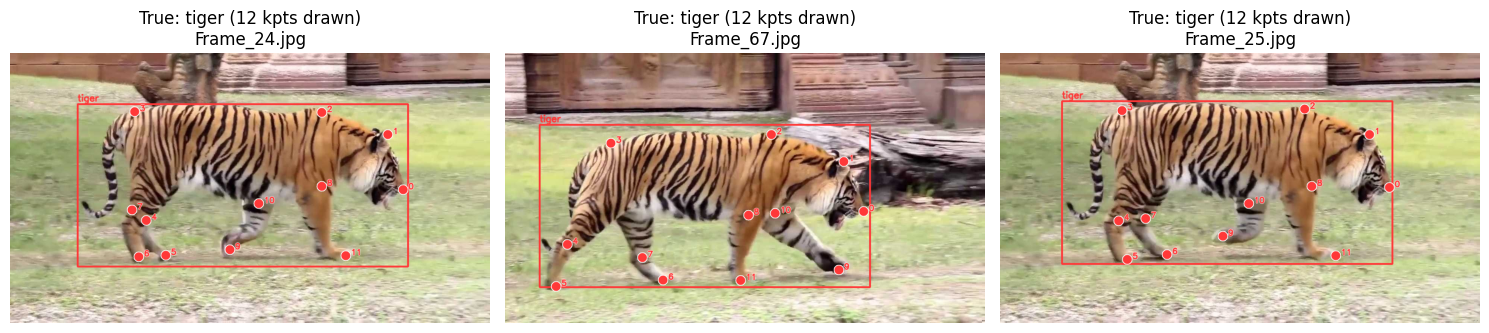

Shown: ['Frame_24.jpg', 'Frame_67.jpg', 'Frame_25.jpg']


In [17]:
gt_examples = show_ground_truth(val_imgs, NAMES, n=3, seed=0)
print("Shown:", [Path(p).name for p in gt_examples])


### Checkpoint 1: The data is what you expect

**Write your answer below (your own words):**
- Do the printed class names and split counts match the lab tables?

**The class names and split does match with the lab tables.**

- Do the ground-truth overlays line up with the objects?

**The ground-truth overlays do line up with the objects.**


---
## Step 1: Baseline (pretrained model, no training)

Run the COCO-pretrained model **as-is** on five validation images.


### Prediction 1 *(write BEFORE running the baseline)*

What do you expect the COCO-pretrained model to get right and wrong on this dataset? Why?

**We predict that the COCO-pretrained model will not get anything right because it only has one class, person, and we are testing for tigers.**


In [30]:
def show_predictions(
    model,
    img_paths,
    title_prefix="pred",
    true_names=None,
    conf=0.25,
    line_width=4,
    kpt_radius=None,
):
    """Run pose model and display annotated results (Colab-safe).

    Always redraws keypoints at a size scaled to the image so they stay visible
    on both tiger-pose frames (~700px) and large Pexels photos.
    """
    import cv2  # ensure available even if GT helper cell was not re-run

    results = model.predict(
        source=[str(p) for p in img_paths],
        imgsz=IMGSZ,
        conf=conf,
        verbose=False,
    )

    fig, axes = plt.subplots(1, len(results), figsize=(5 * len(results), 5))
    if len(results) == 1:
        axes = [axes]

    for ax, r, p in zip(axes, results, img_paths):
        annotated = r.plot(line_width=line_width)  # BGR
        h, w = annotated.shape[:2]
        s = max(1.0, min(h, w) / 700.0)
        radius = kpt_radius if kpt_radius is not None else max(8, int(round(14 * s)))

        # Always redraw keypoints when the model returned any (BGR: red)
        if getattr(r, "keypoints", None) is not None and r.keypoints is not None:
            try:
                xy = r.keypoints.xy.cpu().numpy()  # (n, n_kpts, 2) pixel coords
                for inst in xy:
                    for px, py in inst:
                        if px <= 0 and py <= 0:
                            continue
                        pt = (int(px), int(py))
                        cv2.circle(annotated, pt, radius + 3, (255, 255, 255), -1)
                        cv2.circle(annotated, pt, radius, (0, 0, 255), -1)
            except Exception as e:
                print("Could not overlay large keypoints:", e)

        ax.imshow(annotated[:, :, ::-1])

        n_pred = 0 if r.boxes is None else len(r.boxes)
        if n_pred:
            pred_ids = [int(c) for c in r.boxes.cls.cpu().tolist()]
            pred_labels = [model.names[i] for i in pred_ids]
            pred_str = ", ".join(pred_labels)
            kpt_note = ""
            if getattr(r, "keypoints", None) is not None and r.keypoints is not None:
                try:
                    kpt_note = f" [{r.keypoints.xy.shape[1]} kpts/instance]"
                except Exception:
                    kpt_note = ""
        else:
            pred_str = "(none)"
            kpt_note = ""

        true_str = None
        if true_names is not None:
            img_path = Path(p)
            label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
            true_labels = []
            if label_path.exists():
                for line in label_path.read_text().strip().splitlines():
                    parts = line.split()
                    if len(parts) < 5:
                        continue
                    cls_id = int(float(parts[0]))
                    true_labels.append(true_names.get(cls_id, str(cls_id)))
            true_str = ", ".join(true_labels) if true_labels else "(none)"

        if true_str is not None:
            ax.set_title(f"True: {true_str}\nPred: {pred_str}{kpt_note}")
        else:
            ax.set_title(f"{title_prefix}\nPred: {pred_str}{kpt_note}\n{Path(p).name}")
        ax.axis("off")

    plt.tight_layout()
    plt.show()
    return results


In [31]:
baseline = YOLO(WEIGHTS)

print("Pretrained model class names:")
print(baseline.names)
print("Number of pretrained classes:", len(baseline.names))


Pretrained model class names:
{0: 'person'}
Number of pretrained classes: 1


In [32]:
# Pose models: compare keypoint shape / count, not just class names
print("\nDataset class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")

# Pretrained COCO-pose uses 17 human keypoints with visibility (kpt_shape=[17, 3])
# Tiger-pose uses 12 keypoints without visibility (kpt_shape=[12, 2])
print("\nPretrained model task:", baseline.task)
try:
    print("Pretrained model kpt_shape:", getattr(baseline.model, "kpt_shape", None) or baseline.model.yaml.get("kpt_shape"))
except Exception as e:
    print("Could not read pretrained kpt_shape directly:", e)
print("Dataset kpt_shape:", data_info.get("kpt_shape"))
print("Class-0 meaning: pretrained -> 'person' | dataset -> 'tiger'")
print("Expected: pretrained ~17 human keypoints vs dataset 12 tiger keypoints.")


Dataset class names:
  0: tiger

Pretrained model task: pose
Pretrained model kpt_shape: [17, 3]
Dataset kpt_shape: [12, 2]
Class-0 meaning: pretrained -> 'person' | dataset -> 'tiger'
Expected: pretrained ~17 human keypoints vs dataset 12 tiger keypoints.


Baseline images: ['Frame_24.jpg', 'Frame_67.jpg', 'Frame_25.jpg', 'Frame_113.jpg', 'Frame_191.jpg']
Note: baseline is COCO-pose (class 'person', 17 human keypoints). Empty Pred is expected if it does not fire on tigers.


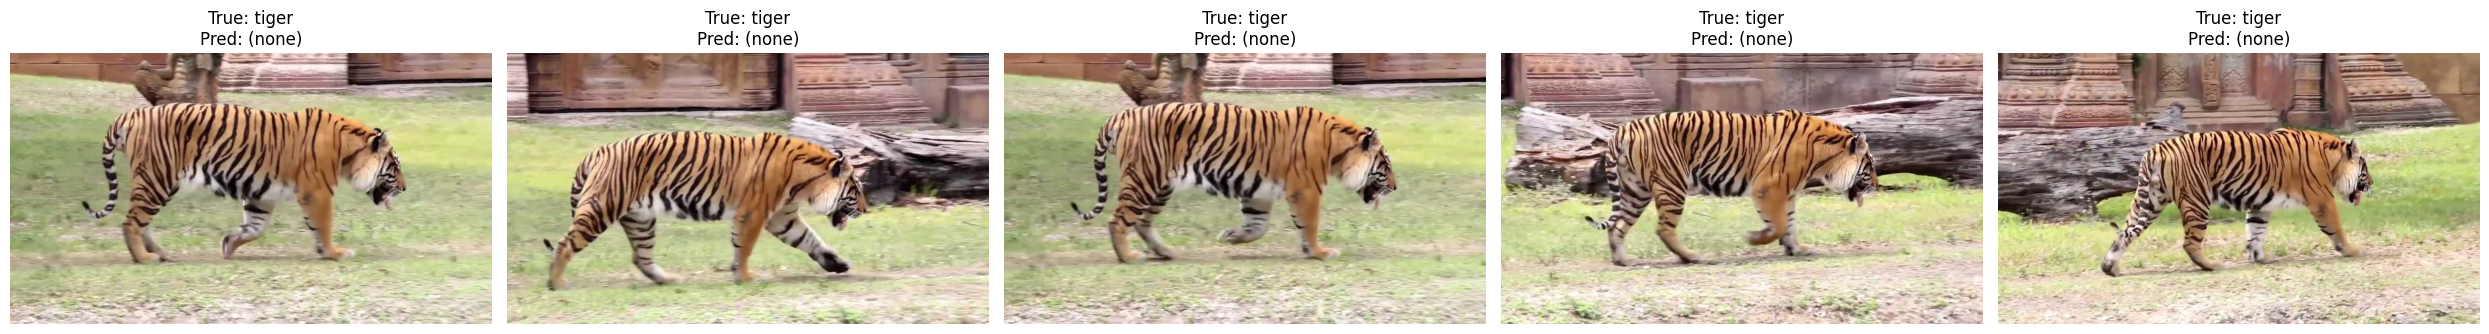


Baseline summary:
  Frame_24.jpg: Pred=(none) — no 'person' detection above conf threshold
  Frame_67.jpg: Pred=(none) — no 'person' detection above conf threshold
  Frame_25.jpg: Pred=(none) — no 'person' detection above conf threshold
  Frame_113.jpg: Pred=(none) — no 'person' detection above conf threshold
  Frame_191.jpg: Pred=(none) — no 'person' detection above conf threshold


In [33]:
# Five validation images (fixed seed so your write-up is reproducible)
rng = random.Random(0)
baseline_imgs = rng.sample(val_imgs, k=min(5, len(val_imgs)))
print("Baseline images:", [Path(p).name for p in baseline_imgs])
print(
    "Note: baseline is COCO-pose (class 'person', 17 human keypoints). "
    "Empty Pred is expected if it does not fire on tigers."
)

baseline_results = show_predictions(
    baseline,
    baseline_imgs,
    title_prefix="baseline",
    true_names=NAMES,  # dataset GT for True:; pretrained model.names for Pred:
)

# Per-image summary for Checkpoint 2 write-up
print("\nBaseline summary:")
for p, r in zip(baseline_imgs, baseline_results):
    n_pred = 0 if r.boxes is None else len(r.boxes)
    if n_pred:
        labels = [baseline.names[int(c)] for c in r.boxes.cls.cpu().tolist()]
        confs = [round(float(c), 3) for c in r.boxes.conf.cpu().tolist()]
        print(f"  {Path(p).name}: Pred={labels} confs={confs}")
    else:
        print(f"  {Path(p).name}: Pred=(none) — no 'person' detection above conf threshold")

### Checkpoint 2: Why the baseline fails

**Write your answer below (your own words):**
- Compare the pretrained model's class names (or keypoint count) with the dataset's. What went wrong in your five images?

**There were no humans and the model is fit for only one class, humans. So, when it saw a tiger it partly made the right decison by not classifying it as a human.**

- Explain why a baseline mAP computed on this dataset with the pretrained model would be meaningless. Hint: what does class 0 mean to each one?

**Baseline mAP computed on this dataset would be meaningless because mAP needs matching meanings for correct class. Here the integers mean different things. In the pre-trained model, 0 means human while in the tiger pose dataset, 0 means tiger.**

**Task-specific:** The pretrained model predicts 17 human keypoints. What happened when it saw a tiger?

**It decided to not predict anything since it only saw a tiger and no humans were present. It was looking for a person with 17 human keypoints but a tiger (12 keypoints) does not match that. The model is not just incorrectly detecting the wrong tiger pose, rather no useful pose at all.**


---
## Step 2: Fine-tuning (transfer learning)

Start from the pretrained weights and train on this dataset with the required settings.


### Prediction 2 *(write BEFORE training)*

What mAP50 do you expect after fine-tuning? How many epochs do you think you'll need (within 50–150)?

**We expect around a 0.80 mAP50. We will use 100 epochs, which is somewhere in the middle. We want to use this amount of epochs because the dataset is small so more epochs help, but at the same time too many could cause overfitting.**

Then set `EPOCHS` in the config cell above to match your choice, and re-run that cell before training.


In [22]:
# Fine-tune. Watch the training log for the "Transferred X/Y items" line.
ft_model = YOLO(WEIGHTS)

train_results = ft_model.train(
    data=DATA_YAML,
    epochs=EPOCHS,
    imgsz=IMGSZ,
    batch=BATCH,
    seed=SEED,
    project=str(PROJECT_DIR),
    name=RUN_NAME,
    exist_ok=True,  # avoid detect_run2 / detect_run3 confusion
)


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=tiger-pose.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n-pose.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=pose_run, nbs=64, nms=None, opset=None, optimize=False, optimizer=aut

### Locate the run directory and display training curves


Run directory: /content/drive/MyDrive/IT480_Lab4/pose/pose_run
Weights: [PosixPath('/content/drive/MyDrive/IT480_Lab4/pose/pose_run/weights/best.pt'), PosixPath('/content/drive/MyDrive/IT480_Lab4/pose/pose_run/weights/last.pt')]


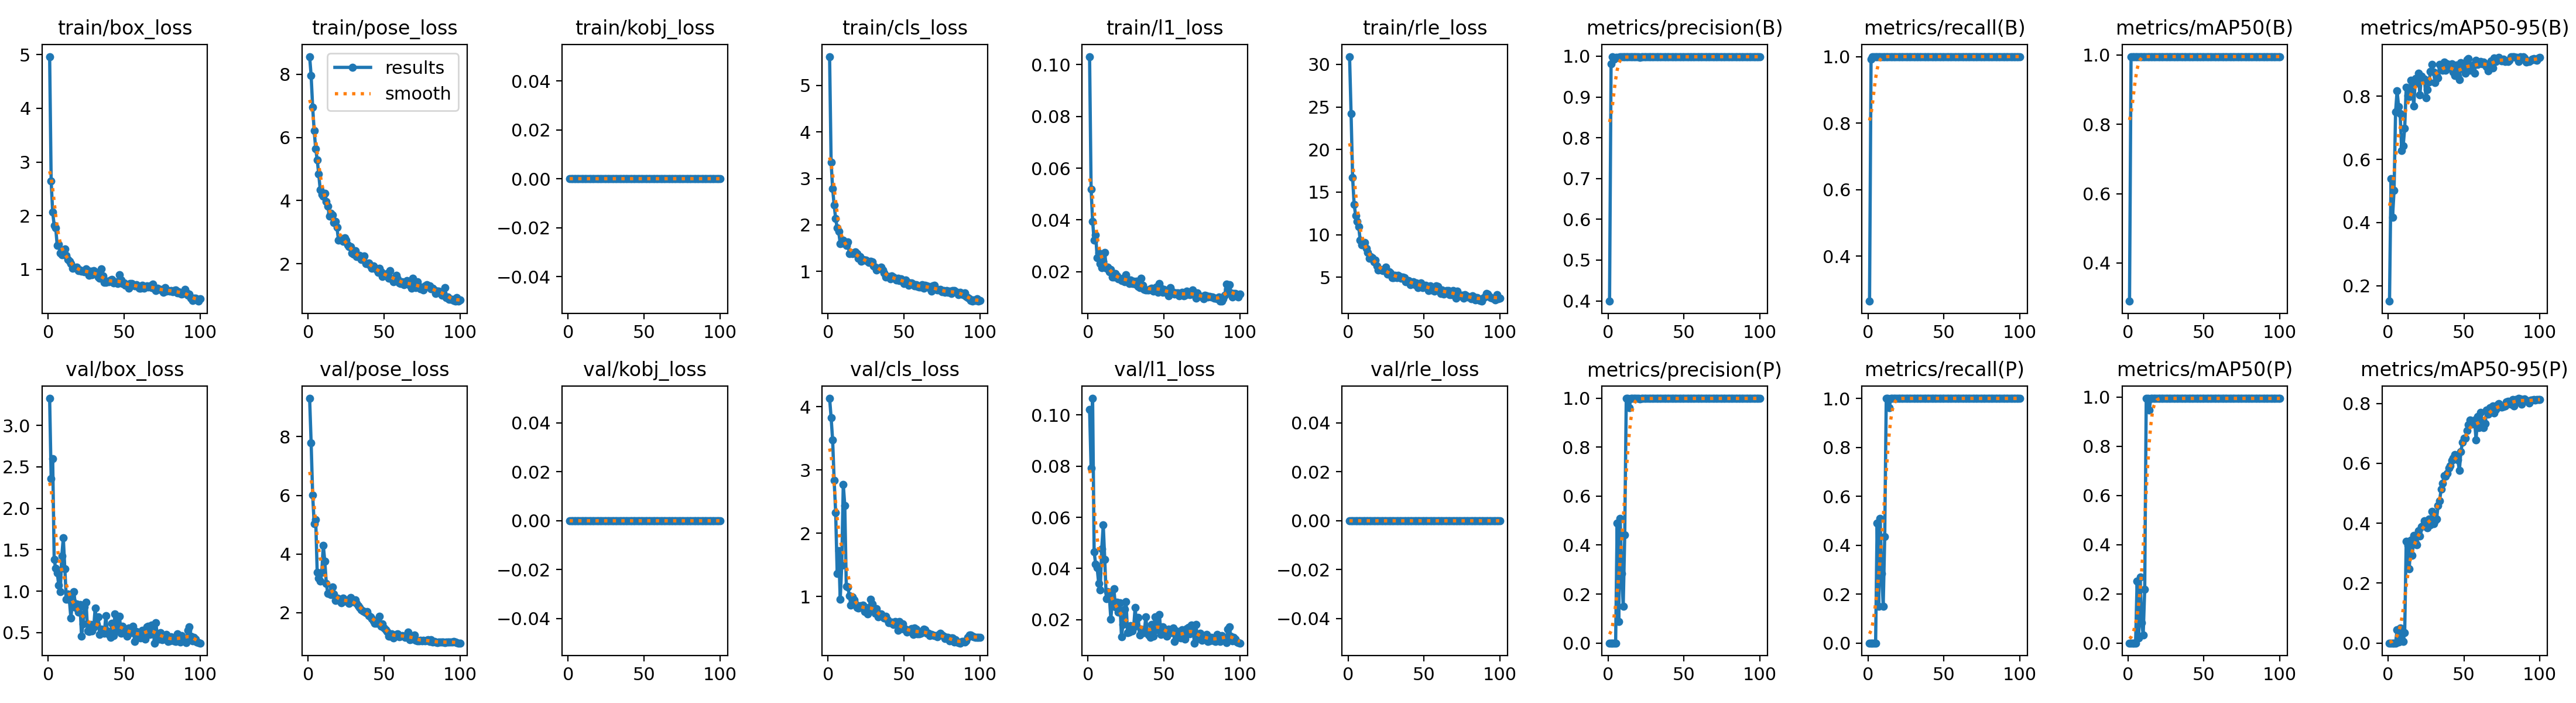

,epoch,time,train/box_loss,train/pose_loss,train/kobj_loss,train/cls_loss,train/l1_loss,train/rle_loss,metrics/precision(B),metrics/recall(B),...,metrics/mAP50-95(P),val/box_loss,val/pose_loss,val/kobj_loss,val/cls_loss,val/l1_loss,val/rle_loss,lr/pg0,lr/pg1,lr/pg2
95,96,664.610,0.45760,0.83833,0,0.38042,0.01159,2.58281,0.99872,1.0,...,0.81329,0.44340,1.01448,0,0.35830,0.01311,0,0.000119,0.000119,0.000119
96,97,674.056,0.46531,0.81746,0,0.36942,0.01166,2.31924,0.99874,1.0,...,0.81095,0.42021,0.99115,0,0.35154,0.01234,0,0.000099,0.000099,0.000099
97,98,680.302,0.43402,0.92598,0,0.40520,0.01081,2.97365,0.99873,1.0,...,0.81246,0.38580,0.96977,0,0.35165,0.01127,0,0.000079,0.000079,0.000079
98,99,690.048,0.40619,0.82471,0,0.35602,0.01019,2.51021,0.99874,1.0,...,0.81317,0.38087,0.96549,0,0.35452,0.01105,0,0.000060,0.000060,0.000060
99,100,696.550,0.44693,0.86084,0,0.37634,0.01131,2.52684,0.99874,1.0,...,0.81346,0.37493,0.96443,0,0.35517,0.01089,0,0.000040,0.000040,0.000040


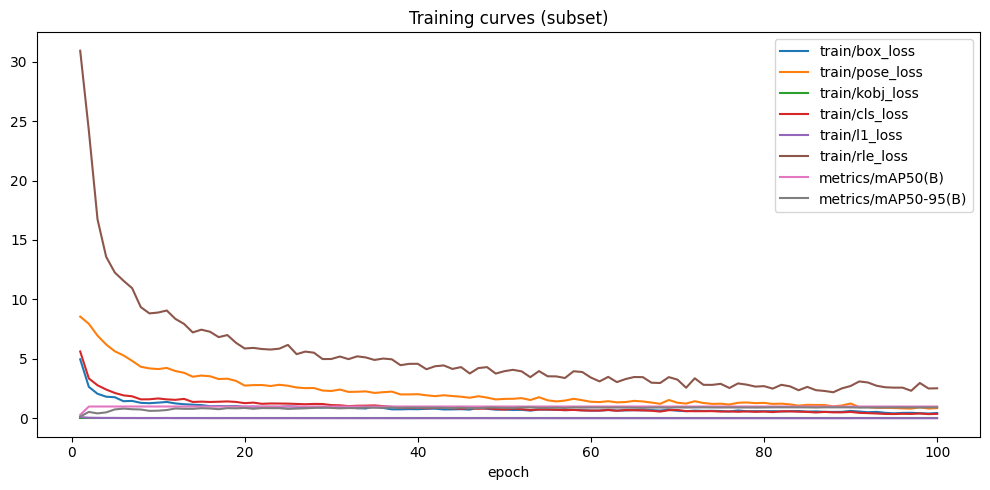

In [23]:
# Ultralytics writes under project/name (and may append a suffix if exist_ok=False)
RUN_DIR = Path(ft_model.trainer.save_dir)
print("Run directory:", RUN_DIR)
print("Weights:", list((RUN_DIR / "weights").glob("*.pt")))

results_png = RUN_DIR / "results.png"
results_csv = RUN_DIR / "results.csv"

if results_png.exists():
    display(IPImage(filename=str(results_png)))
else:
    print("results.png not found yet")

if results_csv.exists():
    curves = pd.read_csv(results_csv)
    curves.columns = [c.strip() for c in curves.columns]
    display(curves.tail())

    # Plot a few key columns if present
    plot_cols = [c for c in curves.columns if any(k in c for k in ("map", "mAP", "loss", "precision", "recall"))]
    # Prefer a compact set
    preferred = [c for c in curves.columns if c in {
        "epoch",
        "metrics/mAP50(B)", "metrics/mAP50-95(B)",
        "metrics/mAP50(M)", "metrics/mAP50-95(M)",
        "metrics/mAP50(P)", "metrics/mAP50-95(P)",
        "train/box_loss", "val/box_loss",
        "train/cls_loss", "val/cls_loss",
        "train/dfl_loss", "val/dfl_loss",
        "train/pose_loss", "val/pose_loss",
        "train/kobj_loss", "val/kobj_loss",
        "train/seg_loss", "val/seg_loss",
    } or "mAP50" in c or c.endswith("_loss")]

    cols_to_plot = [c for c in preferred if c != "epoch" and c in curves.columns]
    if cols_to_plot:
        ax = curves.plot(x="epoch" if "epoch" in curves.columns else None, y=cols_to_plot[:8], figsize=(10, 5))
        ax.set_title("Training curves (subset)")
        plt.tight_layout()
        plt.show()

In [24]:
# Confirm the fine-tuned model now uses the dataset class names
best_path = RUN_DIR / "weights" / "best.pt"
assert best_path.exists(), f"Missing best.pt at {best_path}"

ft_best = YOLO(str(best_path))
print("Fine-tuned model class names:")
for i, name in ft_best.names.items():
    print(f"  {i}: {name}")

print("\nDataset class names:")
for i, name in NAMES.items():
    print(f"  {i}: {name}")

print("\nNames match:", dict(ft_best.names) == dict(NAMES))

Fine-tuned model class names:
  0: tiger

Dataset class names:
  0: tiger

Names match: True


### Checkpoint 3: Transfer learning did what you intended

**Write your answer below (your own words):**
- Find the line `Transferred X/Y items` in the training log. Which parts of the network could not be transferred from the pretrained model, and why?

**The line mentioned above was displayed as "Transferred 795/879 items from pretrained weights". It failed to transfer parts of the network from the pre-trained model because there was an additional keypoints value.**

- Do the fine-tuned model's class names now match the dataset?

**The fine-tuned models class names now match the dataset.**

- Justify your epoch choice using the training curves. Enough? Still improving? Any overfitting in validation losses?

**Our epoch choice was significant because the mAP was extremely high and no overfitting in validation losses is occuring.**

**Task-specific:** The log overrides `kpt_shape=[17, 3]` with `kpt_shape=[12, 2]`. What do those numbers mean, and why does that stop the keypoint layers from being transferred?

**The first regards the COCO pre-trained model and means there are 17 human body points and each point is (x, y, v) where "v" means visibility. On the other hand, the are 12 tiger points and each point is just (x, y). This means that some of the human keypoints are being lost and are not transferred since the tiger metric does not have a visibility flag.**


---
## Step 3: Evaluation

Evaluate **`best.pt`** (not `last.pt`) on the **val** split.


In [34]:
# Honest evaluation on the held-out split specified by the lab
metrics = ft_best.val(
    data=DATA_YAML,
    split="val",
    imgsz=IMGSZ,
    plots=True,
)

print("\n--- Box metrics ---")
print(f"box mAP50:     {metrics.box.map50:.4f}")
print(f"box mAP50-95:  {metrics.box.map:.4f}")

print("\n--- Pose metrics (OKS-based) ---")
print(f"pose mAP50:     {metrics.pose.map50:.4f}")
print(f"pose mAP50-95:  {metrics.pose.map:.4f}")

# Ultralytics can leave sticky val-mode state on the model object after .val().
# Reload best.pt before any later .predict() calls (real-world / failure analysis).
best_path = RUN_DIR / "weights" / "best.pt"
ft_best = YOLO(str(best_path))
print("\nReloaded ft_best from", best_path, "for clean predict() after val.")


Ultralytics 8.4.198 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n-pose summary (fused): 129 layers, 2,634,591 parameters, 0 gradients, 6.3 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 4456.0±690.2 MB/s, size: 204.6 KB)
val: Scanning /content/datasets/tiger-pose/labels/val.cache... 53 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 53/53 15.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Pose(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.0it/s 2.0s
                   all         53         53      0.999          1      0.995      0.925      0.999          1      0.995      0.816
Speed: 4.9ms preprocess, 6.6ms inference, 0.0ms loss, 2.5ms postprocess per image
Results saved to /content/runs/pose/val-2

--- Box metrics ---
box mAP50:     0.9950
box mAP50-95:  0.9253

--- Pose metrics (OKS-based) ---
pose mAP50:     0.9950
pose mAP50-95:  0.8156

Reloaded ft_best from /content/d

### Results table

| Model | Epochs | Split | mAP50 | mAP50-95 |
| --- | --- | --- | --- | --- |
| Baseline (pretrained) | — | — | Not meaningful (see Checkpoint 2) | — |
| Fine-tuned box (`best.pt`) | 100 | `val` | 0.995 | 0.925 |
| Fine-tuned pose (`best.pt`) | 100 | `val` | 0.995 | 0.817 |


Fill in the blanks from the `val` output above.


### Checkpoint 4: Reading the metrics

**Write your answer below (your own words):**
- Report mAP50 and mAP50-95 (and fill the table).

**The mAP50 has been reported above.**

- In one sentence, what does your mAP50 mean in plain language?

**Our mAP50 means that the fine-tuned model has an extremely high accuracy.**

- Why is the test score a fairer measure than the validation score shown during training? (For pose: there is no test split — discuss how much you should trust val.)

**During training, YOLO checks the validation set across all epochs and keeps the weights that look the best. On the other hand, the test set is not used to update weights, we evaluate it once at the end which is why it is a better metric to use to evaluate performance.**

**Task-specific:** Tiger-pose has no test split, so you evaluated on validation. How much should you trust this number, given 53 val images and that validation was used to choose `best.pt`?

**We trust this moderately. There are only 53 images so the estimate is not too concrete and best.pt was picked using validation performance, so the reported mAP50 is a little optimistic. So, this is useful for comparing runs and confirminig that the model learned but there could be a stronger final conclusion.**


---
## Step 4: Real-world test

Use **three** images (or one clip ≤15s) from a free-license site (Pexels, Pixabay, Unsplash). Not from the dataset.


### Prediction 3 *(write BEFORE running inference)*

Which of your real-world images will be hardest for the model? Why?

**We think the tiger in the snow image will be the most difficult because the tigers full body is not displayed, rather it is a frontal view, so the model may not be able to detect all the keypoints.**


Low-conf probe (conf=0.05) before display:
  pexels-photo-12677485.jpeg: n=0 labels=[] confs=[]
  pexels-photo-572861.jpeg: n=0 labels=[] confs=[]
  pexels-photo-302304.jpeg: n=0 labels=[] confs=[]


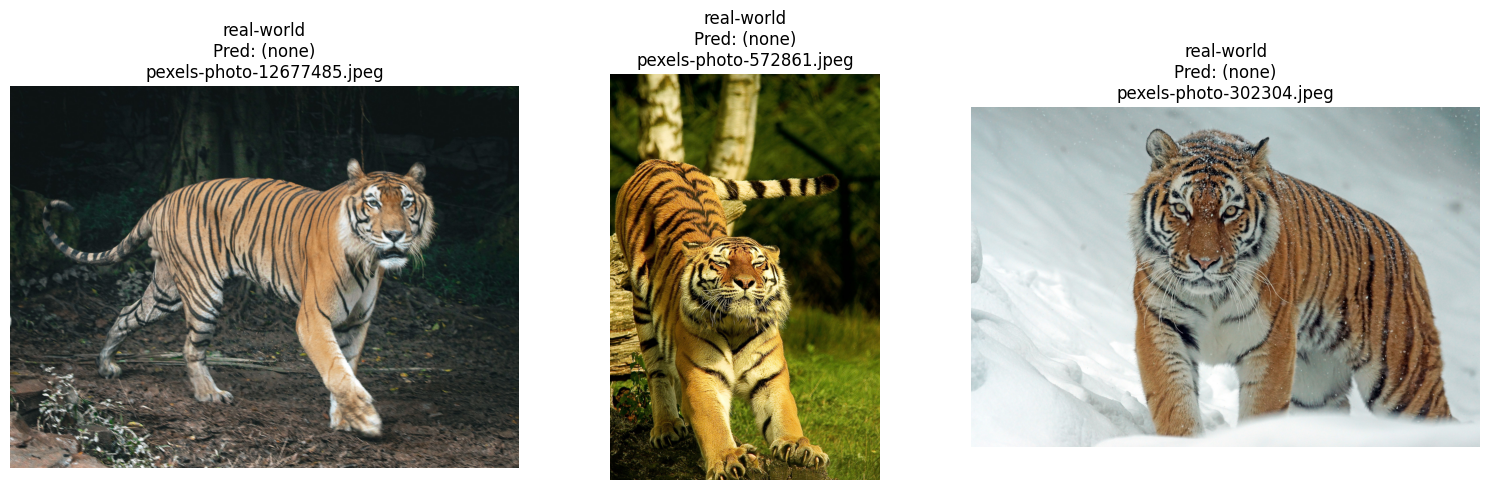

In [35]:
# Three free-license tiger photos from Pexels (Pexels License).
# Direct image URLs for inference; page URLs are listed in Checkpoint 5.
REAL_WORLD_SOURCES = [
    "https://images.pexels.com/photos/12677485/pexels-photo-12677485.jpeg",  # walking tiger, full body
    "https://images.pexels.com/photos/572861/pexels-photo-572861.jpeg",    # tiger stretching / play-bow
    "https://images.pexels.com/photos/302304/pexels-photo-302304.jpeg",    # tiger in snow, frontal
]

assert len(REAL_WORLD_SOURCES) >= 1, "Add real-world image/clip URL(s) before running."

# Fresh load avoids empty preds after model.val() (sticky predictor/overrides).
best_path = RUN_DIR / "weights" / "best.pt"
ft_best = YOLO(str(best_path))

# Quick sanity check: low-conf scan so we can tell "no box" vs "box below 0.25"
print("Low-conf probe (conf=0.05) before display:")
for url in REAL_WORLD_SOURCES:
    r = ft_best.predict(source=url, imgsz=IMGSZ, conf=0.05, verbose=False)[0]
    n = 0 if r.boxes is None else len(r.boxes)
    confs = [round(float(c), 3) for c in r.boxes.conf.cpu().tolist()] if n else []
    labels = [ft_best.names[int(c)] for c in r.boxes.cls.cpu().tolist()] if n else []
    print(f"  {Path(url).name}: n={n} labels={labels} confs={confs}")

rw_results = show_predictions(ft_best, REAL_WORLD_SOURCES, title_prefix="real-world", conf=0.25)


### Checkpoint 5: Sources and results

**Write your answer below (your own words):**
- List each image's source URL and license.
- Was Prediction 3 right? What is different about real-world images vs. the dataset?

| # | Source URL | License | Notes |
| --- | --- | --- | --- |
| 1 | https://www.pexels.com/photo/a-dangerous-tiger-walking-12677485/ | Pexels License (free to use) | Tiger walking in a forest |
| 2 | https://www.pexels.com/photo/572861/ | Pexels License (free to use) | Tiger stretching on a log |
| 3 | https://www.pexels.com/photo/302304/ | Pexels License (free to use) | Tiger walking in snow |

**Prediction 3 was incorrect. The model failed to predict the imags. Real-world images contain tigers in many different positions and they can all be facing different directions. The dataset just contains images of tigers doing very similar poses, so the poses are easier to predict. When given an image of a tiger that is stretching rather than walking or facing directly towards the screen, the model failed to predict it.**


---
## Step 5: Failure analysis

Find one honest failure of the fine-tuned model (missed object, wrong class, bad outline, or misplaced keypoints).


Scanned 53 val images; found 0 count/label mismatches, 0 large keypoint errors (threshold=0.12; 0 skipped)

No val mismatches or large keypoint errors — using the real-world stretch image (missed detection) for Checkpoint 6.
Showing failure case: https://images.pexels.com/photos/572861/pexels-photo-572861.jpeg
True: ['tiger']  (expected; no GT label file for URL images)
Pred: (none) — model missed the tiger
Why flagged: real-world unusual pose / out-of-distribution (stretch / play-bow)


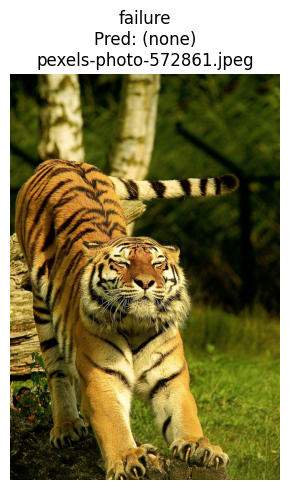

In [36]:
# Find one honest failure for Checkpoint 6.
# Tiger-pose val is nearly perfect on class/count, so:
#   1) collect real mismatches (missed tiger / extra box) on val
#   2) else keep only LARGE keypoint errors (not "worst of a good set")
#   3) else fall back to the known real-world miss (stretch / play-bow)
from collections import Counter

KPT_ERR_THRESHOLD = 0.12  # normalized mean L2; ~0.05 is typical good pose on this set


def gt_pose_labels(img_path):
    """Return (class_names, list of kpts_xy_norm[12,2]) from the YOLO pose label file."""
    label_path = Path(str(img_path).replace("/images/", "/labels/")).with_suffix(".txt")
    names, kpts_list = [], []
    if not label_path.exists():
        return names, kpts_list
    for line in label_path.read_text().strip().splitlines():
        parts = list(map(float, line.split()))
        if len(parts) < 5 + 12 * 2:
            continue
        cls_id = int(parts[0])
        names.append(NAMES.get(cls_id, str(cls_id)))
        kpts_list.append(np.array(parts[5:5 + 24], dtype=np.float32).reshape(12, 2))
    return names, kpts_list


def keypoint_mean_l2(gt_kpts, pred_kpts):
    """Mean L2 in normalized coords; ignore GT points near (0, 0)."""
    n = min(len(gt_kpts), len(pred_kpts))
    gt = np.asarray(gt_kpts[:n], dtype=np.float32)
    pr = np.asarray(pred_kpts[:n], dtype=np.float32)
    if pr.ndim != 2 or pr.shape[1] < 2:
        return None
    pr = pr[:, :2]
    mask = ~((gt[:, 0] <= 1e-6) & (gt[:, 1] <= 1e-6))
    if int(mask.sum()) == 0:
        return None
    return float(np.linalg.norm(gt[mask] - pr[mask], axis=1).mean())


mismatch_candidates = []
pose_error_candidates = []
skipped = 0

for p in val_imgs:
    true_labels, gt_kpts_list = gt_pose_labels(p)
    r = ft_best.predict(source=str(p), imgsz=IMGSZ, verbose=False)[0]

    n_pred = 0 if r.boxes is None else len(r.boxes)
    pred_labels = [ft_best.names[int(c)] for c in r.boxes.cls.cpu().tolist()] if n_pred else []
    confs = [round(float(c), 3) for c in r.boxes.conf.cpu().tolist()] if n_pred else []

    count_diff = abs(n_pred - len(true_labels))
    label_mismatch = Counter(pred_labels) != Counter(true_labels)
    if count_diff > 0 or label_mismatch:
        mismatch_candidates.append(
            {
                "path": p,
                "true": true_labels,
                "pred": pred_labels,
                "confs": confs,
                "score": float(count_diff),
                "reason": (
                    f"count/label mismatch (gt={len(true_labels)}, pred={n_pred})"
                    if count_diff
                    else "class multiset mismatch"
                ),
            }
        )
        continue

    # Same count + labels: only keep clearly bad keypoints
    if n_pred >= 1 and gt_kpts_list and r.keypoints is not None:
        try:
            pred_xy = r.keypoints.xyn.cpu().numpy()
            if pred_xy.ndim == 3:
                pred_xy = pred_xy[0]
            err = keypoint_mean_l2(gt_kpts_list[0], pred_xy)
        except Exception as e:
            err = None
            skipped += 1
            print(f"skip {Path(p).name}: {e}")

        if err is not None and err >= KPT_ERR_THRESHOLD:
            pose_error_candidates.append(
                {
                    "path": p,
                    "true": true_labels,
                    "pred": pred_labels,
                    "confs": confs,
                    "score": err,
                    "reason": f"mean keypoint L2={err:.4f} (normalized, threshold={KPT_ERR_THRESHOLD})",
                }
            )
        elif err is None:
            skipped += 1

mismatch_candidates.sort(key=lambda d: -d["score"])
pose_error_candidates.sort(key=lambda d: -d["score"])

print(
    f"Scanned {len(val_imgs)} val images; "
    f"found {len(mismatch_candidates)} count/label mismatches, "
    f"{len(pose_error_candidates)} large keypoint errors "
    f"(threshold={KPT_ERR_THRESHOLD}; {skipped} skipped)"
)

fail_candidates = mismatch_candidates if mismatch_candidates else pose_error_candidates
for i, d in enumerate(fail_candidates[:10]):
    print(
        f"[{i}] {Path(d['path']).name}: true={d['true']} | pred={d['pred']} | "
        f"confs={d['confs']} | {d['reason']}"
    )

if fail_candidates:
    FAIL_INDEX = 0  # change to pick another from the list above
    fail = fail_candidates[FAIL_INDEX]
    fail_img = fail["path"]
    print("\nShowing failure case:", fail_img)
    print("True:", fail["true"])
    print("Pred:", fail["pred"])
    print("Why flagged:", fail["reason"])
    _ = show_predictions(ft_best, [fail_img], title_prefix="failure", true_names=NAMES)
    _ = show_ground_truth([fail_img], NAMES, n=1, seed=0)
else:
    # Honest failure already seen in Step 4: stretch / play-bow → Pred=(none)
    print(
        "\nNo val mismatches or large keypoint errors — "
        "using the real-world stretch image (missed detection) for Checkpoint 6."
    )
    fail_img = REAL_WORLD_SOURCES[1]
    print("Showing failure case:", fail_img)
    print("True: ['tiger']  (expected; no GT label file for URL images)")
    print("Pred: (none) — model missed the tiger")
    print("Why flagged: real-world unusual pose / out-of-distribution (stretch / play-bow)")
    _ = show_predictions(ft_best, [fail_img], title_prefix="failure")


### Checkpoint 6: One honest failure

**Write your answer below (your own words):**
- Show/describe the failure case.

**The failure case is the real-world image of the tiger stretching on the log. The model predicted nothing (Pred: (none)), even though there is clearly a tiger in the photo.**

- Name the likely cause: small object, occlusion, unusual angle, lighting, out-of-distribution, or other.

**Unusual angle / out-of-distribution.**

- In 2–3 sentences, explain why that cause produced the failure.

**The tiger-pose training images are mostly tigers walking or standing in similar side views, so the model learned that kind of pose really well. In this picture the tiger is stretched out / play-bowing in a pose the dataset barely has, so it looks out-of-distribution. Because of that, the fine-tuned model missed the tiger completely instead of placing a box and the 12 keypoints.**


---
## Reflection questions

Answer in your own words, using your results as evidence. **Do not use AI to write these.**


### Notebook 3 — answer all four

1. Compare your predictions with what actually happened. Which surprised you?

**Prediction 1 was pretty much right — the baseline did not predict anything on the tiger images because it was looking for people. Prediction 2 was too low; we expected about 0.80 mAP50 after fine-tuning, but we ended up around 0.995, which surprised us. Prediction 3 was wrong too — we thought the snow tiger would be hardest, but the model handled that one and completely missed the stretching tiger instead.**

2. Tiger-pose has only 210 training images. How did transfer learning help with so little data?

**Transfer learning helped because the model already knew how to find edges, textures, and animal shapes from COCO. We only had to retrain the parts that did not match tiger-pose, like the keypoint head when kpt_shape changed from [17, 3] to [12, 2]. That is why we could get really high mAP with only 210 training images and 100 epochs instead of training a pose model from scratch.**

3. Across all three notebooks, which task was hardest for YOLO, and how can you tell from your metrics?

*(Your answer here.)*

4. Describe the most important mistake an AI tool made during this lab. How did you discover it, and what would have happened if you hadn't?

**The biggest mistake was the failure-analysis helper that ranked every validation image by small keypoint error and treated the “worst” one as a failure, even when True and Pred were both tiger. We discovered it because the printed output looked successful and the L2 values were only around 0.05, which is not a real miss. If we had not caught that, Checkpoint 6 would have shown a mostly correct val pose instead of the honest real-world failure where the stretching tiger got Pred: (none).**


---
## AI log

Record important AI interactions (aim for 3–5 entries). Across the three notebooks, at least one entry must describe a case where the AI was wrong or incomplete.

| # | Step | What I needed | What I asked (summary) | What the AI gave me | What I did (accepted / modified / rejected) and why | How I verified it |
| --- | --- | --- | --- | --- | --- | --- |
| 1 | Step 0–1 display | True/Pred titles; readable keypoints | Update pose display helpers | First baseline titles showed `Pred: (none) [17 kpts/instance]` with no detections; later pred dots were tiny on large Pexels images | Modified: hide kpt count when Pred is none; scale red keypoint radius to image size (match GT ~radius 12 on ~700px frames) | Re-ran baseline + real-world cells; titles and dot sizes looked right |
| 2 | After fine-tune | Print class names for Checkpoint 3 | Fix names-print cell | Escaped f-strings printed literal `{i}: {name}` | Modified: `{i}: {name}` without double braces | Saw `0: tiger` and `Names match: True` |
| 3 | Step 4 | Free-license tiger images | Replace leopard/panther/lion URLs | Three Pexels tiger URLs + Checkpoint 5 table (URL / license / notes) | Accepted | Real-world preds returned `tiger` with 12 keypoints on detections |
| 4 | Step 5 / Checkpoint 6 | One honest failure | Failure-finding helper | Class-multiset helper found 0 mismatches on this strong model → `AssertionError` | Rejected; replaced with ranking val images by mean keypoint L2 vs GT (pose error, not class error), with real-world fallback | Re-run shows ranked worst keypoint-error frames + Pred vs GT plots |
| 5 | Checkpoint 2 | class 0 / kpt_shape meaning | Why baseline mAP is meaningless; `[17,3]` vs `[12,2]` | person vs tiger for class 0; visibility flag only in COCO | Accepted concept help; wrote answers ourselves | Matched log (`Transferred 795/879`, kpt_shape override) and baseline `Pred=(none)` |
